# Sales Performance Analytics – Exploratory Data Analysis


In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
# Works when notebook is opened from the Day 28 folder or its python subfolder
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data"
OUT = ROOT / "outputs"
(OUT / "charts").mkdir(parents=True, exist_ok=True)
(OUT / "analysis_results").mkdir(parents=True, exist_ok=True)

customers = pd.read_csv(DATA / "customers.csv", parse_dates=["signup_date"])
products = pd.read_csv(DATA / "products.csv")
orders = pd.read_csv(DATA / "orders.csv", parse_dates=["order_date"])
items = pd.read_csv(DATA / "order_items.csv")

print("customers:", customers.shape, "products:", products.shape,
      "orders:", orders.shape, "order items:", items.shape)


customers: (150, 5) products: (20, 5) orders: (850, 5) order items: (1326, 7)


In [2]:
# Combine tables and create analysis fields
df = (items.merge(orders, on="order_id", how="left")
      .merge(products, on="product_id", how="left")
      .merge(customers[["customer_id","customer_name","city","signup_date"]],
             on="customer_id", how="left"))
df["revenue"] = df["line_revenue"]
df["estimated_cost"] = df["quantity"] * df["unit_cost"]
df["estimated_profit"] = df["revenue"] - df["estimated_cost"]
df["month"] = df["order_date"].dt.to_period("M").astype(str)
completed = df[df["order_status"].eq("Completed")].copy()
completed.head()


,order_item_id,order_id,product_id,quantity,unit_price_x,discount_pct,line_revenue,customer_id,order_date,region,...,category,unit_price_y,unit_cost,customer_name,city,signup_date,revenue,estimated_cost,estimated_profit,month
1,2,2,5,2,30,0.00,60.00,70,2025-03-27,Central,...,Electronics,30,14,Customer 070,Indore,2025-02-13,60.00,28,32.00,2025-03
2,3,3,8,4,180,0.10,648.00,57,2025-11-03,South,...,Home,180,105,Customer 057,Bengaluru,2024-08-12,648.00,420,228.00,2025-11
3,4,4,19,1,35,0.05,33.25,83,2025-08-07,East,...,Books,35,15,Customer 083,Kolkata,2024-05-16,33.25,15,18.25,2025-08
4,5,4,8,3,180,0.10,486.00,83,2025-08-07,East,...,Home,180,105,Customer 083,Kolkata,2024-05-16,486.00,315,171.00,2025-08
5,6,5,13,2,65,0.00,130.00,98,2025-05-10,East,...,Clothing,65,31,Customer 098,Patna,2025-08-12,130.00,62,68.00,2025-05


In [3]:
# Data quality checks
quality = {
    "duplicate_order_ids": int(orders["order_id"].duplicated().sum()),
    "duplicate_customer_ids": int(customers["customer_id"].duplicated().sum()),
    "missing_order_dates": int(orders["order_date"].isna().sum()),
    "orphan_order_items": int((~items["order_id"].isin(orders["order_id"])).sum()),
    "negative_line_revenue": int((items["line_revenue"] < 0).sum())
}
pd.Series(quality, name="count").to_frame()


,count
duplicate_order_ids,0
duplicate_customer_ids,0
missing_order_dates,0
orphan_order_items,0
negative_line_revenue,0


In [4]:
# Executive KPIs – completed orders only
order_totals = completed.groupby("order_id")["revenue"].sum()
kpis = pd.Series({
    "Total revenue": completed["revenue"].sum(),
    "Estimated profit": completed["estimated_profit"].sum(),
    "Profit margin (%)": 100 * completed["estimated_profit"].sum() / completed["revenue"].sum(),
    "Completed orders": completed["order_id"].nunique(),
    "Unique customers": completed["customer_id"].nunique(),
    "Average order value": order_totals.mean()
})
kpis.round(2)


Total revenue          182686.00
Estimated profit        79127.00
Profit margin (%)          43.31
Completed orders          784.00
Unique customers          149.00
Average order value       233.02
dtype: float64

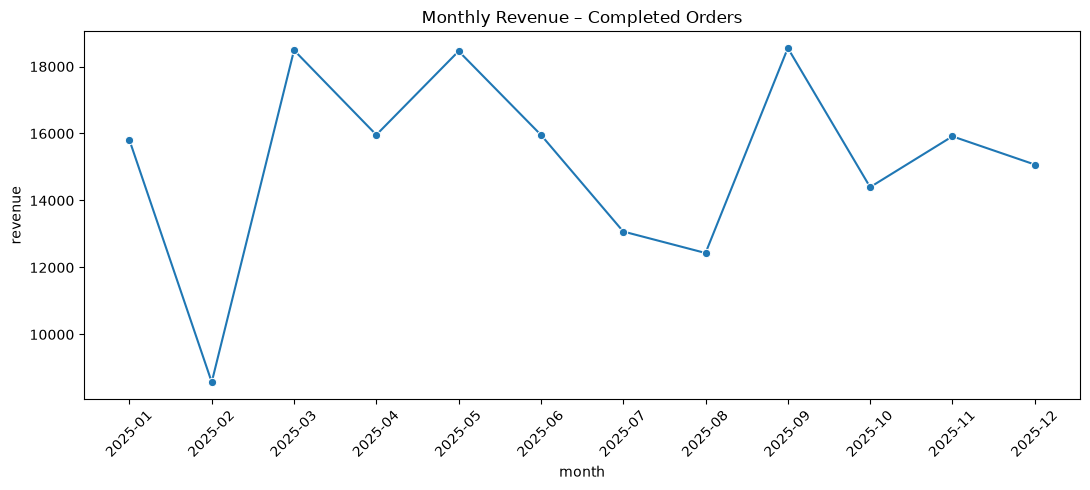

,month,revenue,orders,profit,mom_growth_pct
0,2025-01,15804.40,69,6736.40,NaN
1,2025-02,8576.05,47,3976.05,-45.736314
2,2025-03,18486.40,77,8225.40,115.558445
3,2025-04,15959.55,61,6741.55,-13.668697
4,2025-05,18458.40,77,8109.40,15.657396
5,2025-06,15958.00,67,6929.00,-13.546136
6,2025-07,13073.40,65,5817.40,-18.076200
7,2025-08,12431.55,68,5617.55,-4.909587
8,2025-09,18551.60,66,7737.60,49.229983
9,2025-10,14398.20,60,6092.20,-22.388365


In [5]:
# Monthly revenue trend
monthly = completed.groupby("month").agg(
    revenue=("revenue","sum"),
    orders=("order_id","nunique"),
    profit=("estimated_profit","sum")
).reset_index()
monthly["mom_growth_pct"] = monthly["revenue"].pct_change() * 100
monthly.to_csv(OUT / "analysis_results" / "monthly_performance.csv", index=False)
plt.figure(figsize=(11,5))
sns.lineplot(data=monthly, x="month", y="revenue", marker="o")
plt.xticks(rotation=45); plt.title("Monthly Revenue – Completed Orders")
plt.tight_layout(); plt.savefig(OUT / "charts" / "monthly_revenue.png", dpi=150)
plt.show()
monthly


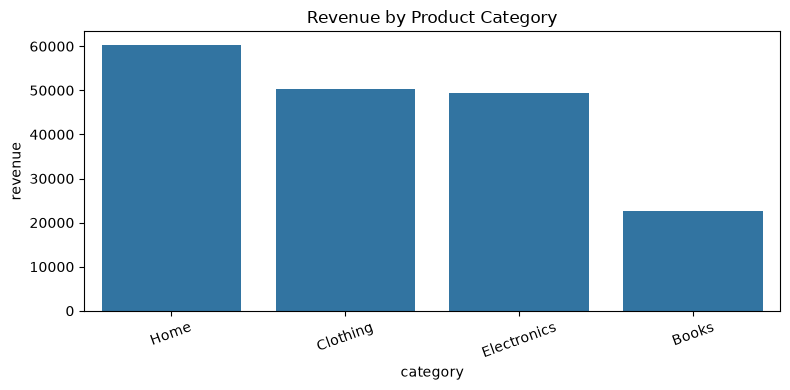

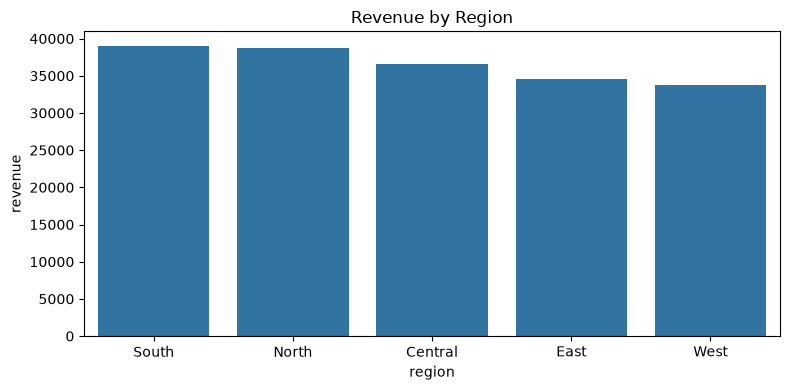

(      category   revenue    profit  units
 0         Home  60364.40  24580.40    844
 1     Clothing  50321.00  23013.00    747
 2  Electronics  49409.75  19329.75    749
 3        Books  22590.85  12203.85    755,
     region   revenue  orders
 0    South  39024.85     152
 1    North  38682.90     171
 2  Central  36595.20     180
 3     East  34595.70     142
 4     West  33787.35     139)

In [6]:
# Category and regional performance
category_perf = completed.groupby("category").agg(
    revenue=("revenue","sum"), profit=("estimated_profit","sum"),
    units=("quantity","sum")
).sort_values("revenue", ascending=False).reset_index()
region_perf = completed.groupby("region").agg(
    revenue=("revenue","sum"), orders=("order_id","nunique")
).sort_values("revenue", ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(data=category_perf, x="category", y="revenue", ax=ax)
ax.set_title("Revenue by Product Category"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(OUT / "charts" / "category_revenue.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(data=region_perf, x="region", y="revenue", ax=ax)
ax.set_title("Revenue by Region")
plt.tight_layout(); plt.savefig(OUT / "charts" / "regional_revenue.png", dpi=150); plt.show()

category_perf, region_perf


In [7]:
# Top products and customers
top_products = completed.groupby("product_name").agg(
    revenue=("revenue","sum"), units=("quantity","sum")
).sort_values("revenue", ascending=False).head(10).reset_index()
top_customers = completed.groupby(["customer_id","customer_name"]).agg(
    revenue=("revenue","sum"), orders=("order_id","nunique")
).sort_values("revenue", ascending=False).head(10).reset_index()
top_products, top_customers


(   product_name   revenue  units
 0  Office Chair  31842.00    189
 1       Monitor  24464.00    118
 2        Jacket  18007.00    173
 3     Bookshelf  16510.00    135
 4      Sneakers  14148.00    167
 5    Headphones   9337.50    132
 6         Jeans   8268.00    138
 7        Hoodie   7601.00    146
 8      Keyboard   6810.75    160
 9  Python Guide   5882.00    156,
    customer_id customer_name  revenue  orders
 0           94  Customer 094  3776.90       9
 1           67  Customer 067  3358.30       9
 2          121  Customer 121  3221.60      12
 3           17  Customer 017  3137.10       6
 4           85  Customer 085  3016.75      11
 5          108  Customer 108  2882.85      10
 6           90  Customer 090  2810.75       8
 7           26  Customer 026  2797.15       8
 8          140  Customer 140  2652.50       8
 9           55  Customer 055  2615.20      10)

In [8]:
# Order status profile – all orders
status_mix = orders["order_status"].value_counts().rename_axis("status").reset_index(name="orders")
status_mix["share_pct"] = 100 * status_mix["orders"] / status_mix["orders"].sum()
status_mix


,status,orders,share_pct
0,Completed,784,92.235294
1,Returned,36,4.235294
2,Cancelled,30,3.529412


In [9]:
# Persist the four CSV tables into a local SQLite database for SQL practice
db_path = DATA / "sales_analytics.db"
with sqlite3.connect(db_path) as conn:
    customers.to_sql("customers", conn, if_exists="replace", index=False)
    products.to_sql("products", conn, if_exists="replace", index=False)
    orders.to_sql("orders", conn, if_exists="replace", index=False)
    items.to_sql("order_items", conn, if_exists="replace", index=False)

with sqlite3.connect(db_path) as conn:
    sql_kpi = pd.read_sql_query('''
        SELECT COUNT(DISTINCT o.order_id) AS completed_orders,
               ROUND(SUM(i.line_revenue),2) AS revenue
        FROM orders o JOIN order_items i ON o.order_id=i.order_id
        WHERE o.order_status='Completed'
    ''', conn)
sql_kpi


,completed_orders,revenue
0,784,182686.0


In [10]:
# Export a compact summary for the business-insights document
summary = {
    "total_revenue": round(float(completed["revenue"].sum()),2),
    "estimated_profit": round(float(completed["estimated_profit"].sum()),2),
    "profit_margin_pct": round(float(100*completed["estimated_profit"].sum()/completed["revenue"].sum()),2),
    "completed_orders": int(completed["order_id"].nunique()),
    "unique_customers": int(completed["customer_id"].nunique()),
    "average_order_value": round(float(order_totals.mean()),2),
    "top_category": str(category_perf.iloc[0]["category"]),
    "top_region": str(region_perf.iloc[0]["region"])
}
pd.Series(summary).to_json(OUT / "analysis_results" / "executive_summary.json", indent=2)
summary


{'total_revenue': 182686.0,
 'estimated_profit': 79127.0,
 'profit_margin_pct': 43.31,
 'completed_orders': 784,
 'unique_customers': 149,
 'average_order_value': 233.02,
 'top_category': 'Home',
 'top_region': 'South'}